# 03. Huấn luyện, Tối ưu Siêu tham số & Đánh giá Isolation Forest (iForest)

---

## PHẦN A: TỔNG QUAN GIAI ĐOẠN 3 (PHASE 3 OVERVIEW)

### 1. Bối cảnh & Vai trò trong Toàn bộ Pipeline
Dự án **Credit Card Fraud Detection** được thiết kế theo kiến trúc Học không giám sát / Phát hiện dị biệt (Unsupervised Anomaly Detection / Novelty Detection) để giải quyết thách thức mất cân bằng lớp cực đoan (chỉ có $0.1727\%$ gian lận).
* **Môn học:** Khai phá Dữ liệu (Data Mining) — Học kỳ 1, Năm 2026 — Học viện Công nghệ Bưu chính Viễn thông (PTIT).
* **Nhóm sinh viên thực hiện:**
  * **Nguyễn Minh Hoàng (B23DCVT173)** — *Modeling & Evaluation Lead*
  * **Nguyễn Văn Hiển Vinh (B23DCVT461)** — *Data & Preprocessing Lead*
* **Vị trí của Phase 3:** Đây là giai đoạn xây dựng **Mô hình Máy học Cốt lõi Đầu tiên (Model 1)** trong bộ ba thuật toán đối chuẩn (Isolation Forest, Local Outlier Factor, One-Class SVM).

### 2. Mục tiêu Kỹ thuật (Technical Objectives)
1. **Huấn luyện Mô hình Cơ sở (Baseline Isolation Forest):** Thiết lập mô hình $100$ cây, lấy mẫu con $256$ giao dịch/cây trên toàn bộ $199,020$ mẫu của tập `Train_Normal` (chỉ gồm giao dịch hợp lệ, không chứa gian lận).
2. **Kiểm chứng Cơ chế Toán học của `contamination` (Contamination Invariance):** Chứng minh bằng lý thuyết và thực nghiệm rằng tham số `contamination` hoàn toàn không thay đổi thứ hạng (Ranking) của Anomaly Score và giữ nguyên chỉ số AUPRC.
3. **Tối ưu hóa Siêu tham số (Grid Search):** Khảo sát lưới 8 cấu hình kết hợp giữa số lượng cây ($n \in [50, 100, 150, 200]$) và kích thước mẫu con ($s \in [256, 512]$), chọn ra mô hình tối ưu theo chỉ số **Average Precision (AP)** trên tập Validation.
4. **Quét Ngưỡng Tối ưu $F_1$ (Threshold Moving):** Xác định ngưỡng cắt $\tau^*$ tối đa hóa $F_1$-score trên tập Validation; trực quan hóa phân phối điểm số và đường cong Precision-Recall Curve.
5. **Thực nghiệm Đánh giá Độ nhạy Trùng lặp (Duplicate Sensitivity Analysis):** Đo lường tác động định lượng của $203$ bản ghi Normal trùng lặp giữa Train và Val đối với các thước đo hiệu năng.
6. **Đóng gói Artifacts Chuẩn mực:** Xuất mô hình tối ưu, bộ tiền xử lý và metadata kỹ thuật phục vụ tái lập quy trình $100\%$.

### 3. Đầu vào (Inputs) & Đầu ra (Outputs)
* **Đầu vào (từ Phase 2):** File dữ liệu tiền xử lý nén `data/processed/creditcard_preprocessed.npz` chứa các ma trận $X_{\text{train}}, y_{\text{train}}, X_{\text{val}}, y_{\text{val}}$ và danh sách $30$ đặc trưng.
* **Đầu ra (bàn giao sang Phase 4–6):**
  * Mô hình tối ưu: `models/isolation_forest_best.joblib`.
  * Bộ tiền xử lý chuẩn: `data/processed/preprocessor.joblib`.
  * Bảng kết quả thực nghiệm: `reports/phase3_isolation_forest_results.csv`.
  * Biểu đồ trực quan: `reports/figures/06_isolation_forest_score_distribution.png` và `07_isolation_forest_pr_curve.png`.
  * Metadata kỹ thuật: `data/processed/pipeline_metadata.json`.
  * Báo cáo tóm tắt: `reports/phase3_isolation_forest_summary.md`.

* **Nguyên tắc Đạo đức Kỹ thuật & Phòng ngừa Rò rỉ (Leakage Prevention):** Cố định `random_state = 42`. Bảo đảm không có Preprocessing Leakage hay Label Leakage. Nhận diện rõ rủi ro Cross-split Duplicate Leakage từ tập dữ liệu gốc Kaggle và kiểm chứng định lượng bằng Sensitivity Analysis (Delta AP = +0.0018). Đồng thời **NIÊM PHONG TUYỆT ĐỐI TẬP TEST SET**, không tải vào bộ nhớ và không sử dụng trong bất kỳ bước nào của Phase 3.

## PHẦN B: CƠ SỞ TOÁN HỌC & NGUYÊN LÝ THUẬT TOÁN ISOLATION FOREST

---

### 1. Nguyên lý Hoạt động Trực giác (Intuitive Principle)
Thuật toán **Isolation Forest (Liu, Ting, Zhou - ICDM 2008 & ACM TKDD 2012)** hoạt động dựa trên triết lý hoàn toàn khác biệt so với các thuật toán phân cụm hay ước lượng mật độ truyền thống:
* Thay vì cố gắng mô hình hóa xem các điểm dữ liệu bình thường trông như thế nào, **Isolation Forest tập trung trực tiếp vào việc cô lập các điểm dị biệt**.
* Các điểm dị biệt (gian lận) có hai thuộc tính bản chất: **(1) Chúng là thiểu số (Few)** và **(2) Chúng có giá trị thuộc tính khác biệt xa so với số đông (Different)**.
* Khi phân chia không gian ngẫu nhiên bằng các siêu phẳng trực giao song song với các trục tọa độ:
  * Điểm gian lận nằm lẻ loi ở vùng biên thưa thớt, nên **chỉ cần rất ít nhát cắt ngẫu nhiên là đã bị cô lập hoàn toàn** $\implies$ Độ dài đường đi từ gốc đến lá rất ngắn.
  * Điểm bình thường nằm chen chúc trong cụm mật độ dày đặc, nên **cần rất nhiều nhát cắt ngẫu nhiên mới cô lập được** $\implies$ Độ dài đường đi từ gốc đến lá rất sâu.

---

### 2. Mô hình Toán học Cốt lõi (Mathematical Formulation)

#### A. Độ dài đường đi (Path Length) $h(x)$
Cho một tập dữ liệu $X = \{x_1, \dots, x_n\}$ gồm các vector $d$ chiều. Một Cây cô lập (Isolation Tree - iTree) là một cây nhị phân chuẩn, trong đó mỗi nút hoặc là nút lá không có con, hoặc là nút trong có đúng hai nút con cùng một phép kiểm tra phân chia:
* Chọn ngẫu nhiên một thuộc tính $q \in \{1, \dots, d\}$.
* Chọn ngẫu nhiên một giá trị ngưỡng cắt $p \in [\min(X_{*, q}), \max(X_{*, q})]$.
* Phân chia: Các mẫu có $x_q < p$ sang nhánh trái, còn lại sang nhánh phải.

Độ dài đường đi $h(x)$ của một mẫu $x$ là số cạnh mà $x$ phải đi qua từ nút gốc của iTree đến khi dừng tại nút lá.

#### B. Hệ số chuẩn hóa cây nhị phân tìm kiếm $c(n)$
Vì cấu trúc iTree có tính chất giải tích tương đương với Cây tìm kiếm nhị phân (Binary Search Tree - BST), độ dài đường đi trung bình của một phép tìm kiếm thất bại trên tập $n$ mẫu được xác định chính xác theo công thức của Preiss (1999):
$$c(n) = 2 \ln(n - 1) + 2\gamma - \frac{2(n - 1)}{n}$$
Trong đó $\gamma \approx 0.5772156649$ là hằng số Euler-Mascheroni. Đại lượng $c(n)$ đóng vai trò là thừa số chuẩn hóa độ sâu trung bình của cây đối với kích thước mẫu $n$.

#### C. Điểm số dị biệt lý thuyết (Anomaly Score) $s(x, n)$
Điểm dị biệt của mẫu $x$ trên một rừng gồm $t$ cây iTree được định nghĩa:
$$s(x, n) = 2^{-\frac{E(h(x))}{c(n)}}$$
Trong đó $E(h(x)) = \frac{1}{t} \sum_{k=1}^t h_k(x)$ là kỳ vọng độ dài đường đi của mẫu $x$ qua toàn bộ $t$ cây.

**Biện luận hành vi toán học của $s(x, n)$:**
* Khi $E(h(x)) \to 0 \implies s(x, n) \to 2^0 = 1$: Mẫu bị cô lập gần như ngay lập tức $\implies$ **Khả năng gian lận cực kỳ cao**.
* Khi $E(h(x)) \to n - 1 \implies s(x, n) \to 2^{-(n-1)/c(n)} \approx 0$: Mẫu cần đi qua độ sâu tối đa mới bị cô lập $\implies$ **Giao dịch hoàn toàn bình thường**.
* Khi $E(h(x)) \to c(n) \implies s(x, n) \to 2^{-1} = 0.5$: Độ sâu thực tế bằng đúng kỳ vọng ngẫu nhiên $\implies$ **Không thể phân biệt rõ ràng dị biệt**.

---

### 3. Ý nghĩa Siêu tham số & Ưu/Nhược điểm Thuật toán

| Tham số | Ý nghĩa kỹ thuật | Giá trị mặc định / Khảo sát | Tác động đến mô hình |
| :--- | :--- | :---: | :--- |
| `n_estimators` | Số lượng cây cô lập trong rừng ($t$) | `[50, 100, 150, 200]` | Càng nhiều cây, điểm số càng ổn định và giảm phương sai; vượt quá 200 cây ít cải thiện thêm nhưng tốn CPU. |
| `max_samples` | Kích thước mẫu con rút ngẫu nhiên để dựng mỗi cây ($\psi$) | `[256, 512]` | Kiểm soát hiện tượng Swamping (che giấu) và Masking (nhiễu). Giá trị $\psi=256$ là mức chuẩn tối ưu lý thuyết của Liu et al. |
| `contamination` | Tỷ lệ ngoại lai ước lượng ngầm định | `['auto', 0.0017, 0.01, 0.05]` | **Chỉ dùng để tính ngưỡng cắt `offset_` cho hàm `predict()`**. Hoàn toàn không ảnh hưởng đến Anomaly Score ranking và AUPRC. |
| `random_state` | Hạt giống ngẫu nhiên để tái lập | `42` | Đảm bảo kết quả phân chia ngẫu nhiên giống hệt nhau $100\%$ qua các lần chạy. |

* **Ưu điểm vượt trội:**
  * **Độ phức tạp tuyến tính $O(t \cdot \psi \log \psi)$:** Thời gian huấn luyện siêu nhanh, có thể chạy trơn tru trên toàn bộ $199,020$ mẫu của tập Train mà không bị tràn RAM như LOF hay OCSVM.
  * **Kháng nhiễu đa chiều:** Lấy mẫu con $\psi=256$ giúp triệt tiêu hiện tượng che giấu vùng dị biệt.
* **Nhược điểm & Hạn chế:**
  * **Nhát cắt trực giao (Axis-aligned Splits):** Các phép phân chia luôn song song với trục tọa độ, có thể tạo ra các vùng dị biệt giả tạo (Artefacts) ở những không gian có đặc trưng tương quan chéo phi tuyến mạnh.
  * Không tận dụng được nhãn giám sát trong quá trình dựng cây (hoàn toàn Unsupervised).

---

### 4. 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ CHUYÊN SÂU PHẦN THUẬT TOÁN)

> **❓ Giảng viên hỏi 1: Isolation Forest là gì và tại sao lại chọn thuật toán này đầu tiên?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô, Isolation Forest là thuật toán học máy không giám sát chuyên biệt cho bài toán phát hiện dị biệt. Thay vì học hình dạng phân phối của dữ liệu bình thường như các mô hình mật độ, iForest tập trung trực tiếp vào việc cô lập các điểm bất thường bằng các nhát cắt nhị phân ngẫu nhiên. Chúng em chọn iForest đầu tiên vì thuật toán có độ phức tạp tính toán tuyến tính rất thấp, mở rộng được trên toàn bộ 199,020 mẫu Train mà không lo tràn RAM, đóng vai trò là thước đo cơ sở (Baseline) vững chắc cho toàn bộ đề tài."*

> **❓ Giảng viên hỏi 2: Một cây cô lập (Isolation Tree) được xây dựng như thế nào?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, để dựng một iTree, thuật toán lấy ngẫu nhiên một mẫu con gồm $\psi=256$ điểm dữ liệu. Tại mỗi nút, thuật toán chọn ngẫu nhiên một thuộc tính $q$, sau đó chọn ngẫu nhiên một giá trị cắt $p$ nằm giữa giá trị nhỏ nhất và lớn nhất của thuộc tính đó để chia đôi dữ liệu. Quá trình chia nhánh đệ quy dừng lại khi: (1) Cây đạt độ sâu giới hạn $h_{\max} \approx \lceil \log_2 \psi \rceil$, (2) Nút chỉ còn lại một mẫu duy nhất, hoặc (3) Tất cả các mẫu tại nút đều có giá trị thuộc tính giống hệt nhau."*

> **❓ Giảng viên hỏi 3: Vì sao độ dài đường đi ngắn lại chứng minh giao dịch là gian lận?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, các giao dịch gian lận mang hai đặc điểm cốt lõi: chúng rất hiếm và có giá trị thuộc tính nằm tách biệt xa khỏi đám đông. Vì nằm ở vùng không gian thưa thớt, xác suất một nhát cắt ngẫu nhiên cô lập được điểm gian lận là rất cao, khiến nó rơi vào nút lá chỉ sau vài lần cắt (độ sâu $h(x)$ rất nhỏ). Ngược lại, giao dịch bình thường nằm chen chúc trong cụm mật độ dày đặc, đòi hỏi rất nhiều nhát cắt tỉ mỉ mới tách được, nên độ sâu $h(x)$ rất lớn."*

> **❓ Giảng viên hỏi 4: Ý nghĩa của hai tham số `n_estimators` và `max_samples` là gì?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, `n_estimators` là số lượng cây cô lập được tạo ra (thường từ 100 đến 200 cây) để tính trung bình độ sâu, giúp giảm phương sai và làm mượt điểm số. Còn `max_samples` là số mẫu con dùng để dựng mỗi cây (mặc định là 256). Giá trị 256 này là kết quả nghiên cứu toán học kinh điển của Liu et al., giúp tránh hiện tượng Swamping (giao dịch bình thường bị coi nhầm là gian lận vì đứng gần cụm gian lận) và hiện tượng Masking (quá nhiều ca gian lận đứng cạnh nhau làm che khuất tính dị biệt)."*

> **❓ Giảng viên hỏi 14: Những hạn chế lớn nhất của Isolation Forest trong thực tế là gì?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, hạn chế lớn nhất của iForest là sử dụng các nhát cắt trực giao song song với trục tọa độ (Axis-aligned splits). Khi dữ liệu có các tương quan chéo phức tạp hoặc ranh giới dị biệt nằm theo đường chéo phi tuyến, iForest có thể tạo ra các vùng đánh giá dị biệt không chính xác ở các góc phần tư. Để bổ khuyết cho hạn chế này và đa dạng hóa góc nhìn phân tích, nhóm em đã tích hợp thêm mô hình Local Outlier Factor (khai thác thông tin mật độ láng giềng cục bộ k-NN) ở Phase 4 và One-Class SVM (khai thác mặt phân cách phi tuyến kernel RBF) ở Phase 5 để đối sánh khách quan, dù bản thân hai mô hình này cũng có những giả định và chi phí tính toán riêng."*

In [1]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO MÔI TRƯỜNG, THƯ VIỆN & THIẾT LẬP PHONG CÁCH ĐỒ HỌA
# ==============================================================================
# • Mục đích: Thiết lập môi trường thực thi chuẩn PEP 8, nạp các thư viện toán học
#   và tái sử dụng các module chuẩn hóa trong src/.
# • Input: Môi trường ảo Python 3.12 (.venv).
# • Output: Các biến môi trường, đường dẫn hệ thống và cấu hình đồ họa sẵn sàng.
# • Nguy cơ rò rỉ: Hoàn toàn không (chỉ khởi tạo môi trường).

import sys
import os
import time
import tracemalloc
import json
from pathlib import Path
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import IsolationForest
from sklearn.metrics import (
    average_precision_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

# Thêm thư mục gốc dự án vào sys.path để gọi module từ src/
sys.path.append(str(Path.cwd().parent))
from src.config import RANDOM_STATE, PROCESSED_DATA_DIR, FIGURES_DIR, ROOT_DIR
MODELS_DIR = ROOT_DIR / "models"
REPORTS_DIR = ROOT_DIR / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

from src.models import build_isolation_forest, compute_unified_anomaly_scores
from src.metrics import compute_auprc, evaluate_threshold

# Cấu hình phong cách hiển thị biểu đồ chuẩn học thuật
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 300
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

print("=" * 70)
print(f"-> Môi trường khởi tạo thành công với RANDOM_STATE = {RANDOM_STATE}")
print(f"-> Python Version: {sys.version.split()[0]} | NumPy: {np.__version__} | Pandas: {pd.__version__}")
print("=" * 70)

-> Môi trường khởi tạo thành công với RANDOM_STATE = 42
-> Python Version: 3.12.10 | NumPy: 2.5.4 | Pandas: 3.1.0


### BƯỚC 2: NẠP DỮ LIỆU ĐÃ TIỀN XỬ LÝ & NGUYÊN TẮC ZERO-LEAKAGE

* **Nhiệm vụ:** Nạp ma trận đặc trưng $X_{\text{train}}, X_{\text{val}}$ và mảng nhãn $y_{\text{train}}, y_{\text{val}}$ từ file nén `data/processed/creditcard_preprocessed.npz`.
* **Tại sao cần thực hiện:** Kế thừa trọn vẹn kết quả chuẩn hóa RobustScaler của Phase 2, không lặp lại code tiền xử lý nhằm đảm bảo tính toàn vẹn (Single Source of Truth).
* **Đầu vào (Input):** `creditcard_preprocessed.npz`.
* **Đầu ra (Output):** Các mảng NumPy trong bộ nhớ RAM, phục vụ huấn luyện và đánh giá.
* **Hậu quả nếu làm sai:** Nếu vô tình nạp và sử dụng `X_test` để chọn mô hình, toàn bộ kết quả thẩm định độc lập tại Phase 8 sẽ bị vô hiệu hóa vì vi phạm quy tắc chống rò rỉ dữ liệu (Data Snooping Leakage).
* **Kiểm tra rò rỉ:** Xác nhận bằng lệnh `assert` rằng $X_{\text{train}}$ có đúng $0$ ca gian lận, và tuyệt đối **KHÔNG NẠP MẢNG `X_test`**.

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN PHÂN CHIA DỮ LIỆU)

> **❓ Giảng viên hỏi 5: Vì sao chỉ fit mô hình trên `Train_Normal` mà loại bỏ toàn bộ Fraud?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô, bản chất của đề tài chúng em là bài toán Phát hiện tính mới (Novelty Detection). Trong môi trường thực tế của ngân hàng, các thủ đoạn gian lận thẻ tín dụng liên tục biến hóa và thay đổi khôn lường; nếu đưa 344 ca gian lận cũ vào tập Train, mô hình sẽ bị thiên kiến (Bias) và chỉ đi tìm những mẫu giống hệt quá khứ. Bằng cách huấn luyện thuần túy trên 199,020 giao dịch hợp lệ, mô hình sẽ học được biên bao đóng thực sự của hành vi người tốt; bất kỳ giao dịch nào đi lệch ra ngoài biên bao đóng này đều sẽ bị cảnh báo ngay lập tức, kể cả những hình thức gian lận hoàn toàn mới chưa từng xuất hiện."*

> **❓ Giảng viên hỏi 13: Vì sao tập Test Set bị niêm phong tuyệt đối ở Phase 3?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, tập Test Set đóng vai trò là bài thi tốt nghiệp cuối cùng trong môi trường sản xuất thực tế. Nếu chúng em sử dụng tập Test để so sánh các siêu tham số của Isolation Forest hay chọn ngưỡng cắt $\tau^*$, thông tin của tập Test sẽ bị thẩm thấu ngầm vào cấu trúc mô hình (hiện tượng Data Snooping Leakage). Kết quả khi đó sẽ bị lạc quan giả tạo. Do đó, toàn bộ việc chọn số cây, kích thước mẫu và quét ngưỡng ở Phase 3 chỉ được phép diễn ra trên tập Validation; tập Test được niêm phong tuyệt đối cho tới Phase 8."*

In [2]:
# ==============================================================================
# BƯỚC 2: NẠP DỮ LIỆU TIỀN XỬ LÝ ZERO-LEAKAGE (TUYỆT ĐỐI KHÔNG NẠP TEST SET)
# ==============================================================================
npz_path = PROCESSED_DATA_DIR / "creditcard_preprocessed.npz"

with np.load(npz_path, allow_pickle=True) as data:
    X_train = data['X_train']
    y_train = data['y_train']
    X_val = data['X_val']
    y_val = data['y_val']
    feature_names = list(data['feature_names'])

# Kiểm tra nghiêm ngặt tính toàn vẹn và nguyên tắc chống rò rỉ dữ liệu
assert len(X_train) == 199020, f"Kích thước X_train không khớp: {len(X_train)}"
assert y_train.sum() == 0, f"[LỖI RÒ RỈ] X_train chứa {y_train.sum()} mẫu Fraud! Bắt buộc phải là 0."
assert len(X_val) == 42721, f"Kích thước X_val không khớp: {len(X_val)}"
assert y_val.sum() == 74, f"Số lượng Fraud trên Validation không khớp: {y_val.sum()}"
assert not np.isnan(X_train).any() and not np.isinf(X_train).any(), "X_train chứa giá trị NaN hoặc Inf!"
assert not np.isnan(X_val).any() and not np.isinf(X_val).any(), "X_val chứa giá trị NaN hoặc Inf!"

print("=" * 70)
print("XÁC NHẬN TÍNH TOÀN VẸN DỮ LIỆU ĐẦU VÀO PHASE 3:")
print(f"• X_train shape : {X_train.shape} | Số lượng Fraud: {y_train.sum():,} (100% Normal)")
print(f"• X_val shape   : {X_val.shape} | Số lượng Fraud: {y_val.sum():,} ({y_val.mean()*100:.4f}%)")
print(f"• Số đặc trưng  : {len(feature_names)} ({', '.join(feature_names[:3])} ... {', '.join(feature_names[-2:])})")
print("• Tập Test Set  : [NIÊM PHONG TUYỆT ĐỐI] - Không được tải vào bộ nhớ.")
print("=" * 70)

XÁC NHẬN TÍNH TOÀN VẸN DỮ LIỆU ĐẦU VÀO PHASE 3:
• X_train shape : (199020, 30) | Số lượng Fraud: 0 (100% Normal)
• X_val shape   : (42721, 30) | Số lượng Fraud: 74 (0.1732%)
• Số đặc trưng  : 30 (V1, V2, V3 ... scaled_amount, scaled_time)
• Tập Test Set  : [NIÊM PHONG TUYỆT ĐỐI] - Không được tải vào bộ nhớ.


### BƯỚC 3: HUẤN LUYỆN MÔ HÌNH CƠ SỞ (BASELINE) & QUY ƯỚC ĐẢO DẤU SCORE

* **Nhiệm vụ:** Khởi tạo mô hình Baseline `IsolationForest(n_estimators=100, max_samples=256, contamination='auto', random_state=42)` và đo lường thời gian thực thi.
* **Tại sao cần thực hiện:** Tạo mốc chuẩn đối sánh (Benchmark) để chứng minh xem việc tinh chỉnh siêu tham số ở các bước sau có thực sự mang lại giá trị gia tăng hay không.
* **Quy ước đảo dấu Anomaly Score & Phân biệt với Xác suất:**
  Trong scikit-learn:
  $$\text{score\_samples}(x) = -2^{-\frac{E(h(x))}{c(n)}}$$
  Hàm này trả về giá trị âm (càng âm sâu càng dị biệt). Để tuân thủ quy ước chuẩn của Khoa học Dữ liệu (**Điểm càng cao $\implies$ Nguy cơ bất thường càng lớn**), ta thực hiện đảo dấu:
  $$S(x) = -\text{score\_samples}(x)$$
  > **[LƯU Ý KHOA HỌC QUAN TRỌNG]:** Điểm $S(x)$ là thước đo mức độ cô lập tương đối trong không gian đặc trưng, **KHÔNG PHẢI là xác suất gian lận đã hiệu chuẩn (Calibrated Probability)**. Một giao dịch có điểm $S(x)$ cao chỉ là một ngoại lai ứng viên (Candidate Outlier) cần được hệ thống giám sát kiểm tra, không thể khẳng định chắc chắn 100% là gian lận.
* **Hậu quả nếu làm sai:** Nếu quên đảo dấu, toàn bộ trục điểm số bị ngược hướng, đường cong Precision-Recall sẽ bị đảo lộn và AUPRC tính ra gần bằng 0!

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN HÀM SCORE & ĐO LƯỜNG METRIC)

> **❓ Giảng viên hỏi 6: Phương thức `score_samples`, `decision_function` và `predict` khác nhau thế nào?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô:  
> 1. `score_samples(X)`: Trả về trực tiếp số đối của điểm dị biệt liên tục theo lý thuyết cây cô lập, tính thuần túy từ độ sâu $E(h(x))$ và độc lập hoàn toàn với tham số `contamination`.  
> 2. `decision_function(X)`: Là điểm `score_samples(X)` trừ đi ngưỡng nội tại `offset_`. Đây chỉ là phép tịnh tiến một hằng số vô hướng, thứ tự xếp hạng của các mẫu không đổi.  
> 3. `predict(X)`: Trả về nhãn nhị phân rời rạc ($+1$ là người tốt, $-1$ là ngoại lai) bằng cách so sánh `decision_function` với số 0. Hàm này phụ thuộc cứng vào tham số `contamination`."*

> **❓ Giảng viên hỏi 7: Vì sao bắt buộc phải đảo dấu Anomaly Score bằng phép trừ (-)?**  
> **🎯 Bạn trả lời:**  
> *"Dạ, các hàm đánh giá đường cong của scikit-learn như `precision_recall_curve` hay `average_precision_score` đều mặc định quy ước rằng: mẫu nào có điểm số dự đoán càng cao thì xác suất hoặc mức độ nghi vấn thuộc về lớp dương tính càng lớn. Tuy nhiên, `IsolationForest.score_samples()` trong scikit-learn lại trả về điểm âm lớn cho các ca bị cô lập nhanh. Do đó, chúng em nhân với $-1$ để đưa điểm số về đúng chiều trực giác: Giao dịch bình thường có điểm thấp, giao dịch có đặc trưng bất thường có điểm cao vượt trội, giúp tính đúng tích phân diện tích AUPRC."*

> **❓ Giảng viên hỏi 9: Vì sao bài toán này dùng Average Precision (AP / AUPRC) thay vì Accuracy hay ROC-AUC?**  
> **🎯 Bạn trả lời:**  
> *"Dạ:  
> 1. Với tỷ lệ gian lận chỉ $0.17\%$, thước đo **Accuracy hoàn toàn vô dụng** vì một mô hình đoán bừa 'tất cả là người tốt' cũng đạt độ chính xác $99.83\%$ nhưng bỏ lọt $100\%$ kẻ gian.  
> 2. **ROC-AUC bị lạc quan giả tạo** vì trục hoành là False Positive Rate (mẫu số là toàn bộ người tốt rất lớn $\approx 42,600$), nên dù báo động nhầm hàng trăm người thì FPR vẫn xấp xỉ 0, khiến ROC-AUC trông rất cao ảo tưởng.  
> 3. **Average Precision (AUPRC)** tập trung độc quyền vào lớp thiểu số (Fraud), tích hợp trực tiếp giữa Precision (độ chuẩn xác cảnh báo) và Recall (tỷ lệ bắt trọn kẻ gian). Đây là tiêu chuẩn vàng được cộng đồng khoa học quốc tế bắt buộc dùng cho imbalanced data."*

In [3]:
# ==============================================================================
# BƯỚC 3: HUẤN LUYỆN MÔ HÌNH BASELINE ISOLATION FOREST
# ==============================================================================
# Khởi tạo mô hình Baseline theo Kế hoạch V2.1
baseline_model = build_isolation_forest(
    n_estimators=100,
    max_samples=256,
    contamination="auto",
    random_state=RANDOM_STATE
)

# 1. Đo thời gian huấn luyện (fit_time) trên 199,020 mẫu Train_Normal
t_start = time.perf_counter()
baseline_model.fit(X_train)
baseline_fit_time = time.perf_counter() - t_start

# 2. Đo thời gian suy luận (scoring_time) trên 42,721 mẫu Validation Set
t_start = time.perf_counter()
baseline_scores = compute_unified_anomaly_scores(baseline_model, X_val, model_name="iForest")
baseline_score_time = time.perf_counter() - t_start

# 3. Đánh giá chỉ số Average Precision (AP) chuẩn xác qua hàm average_precision_score
baseline_ap = average_precision_score(y_val, baseline_scores)

print("=" * 70)
print("KẾT QUẢ BASELINE ISOLATION FOREST TRÊN TẬP VALIDATION:")
print(f"• Thời gian huấn luyện (fit_time)   : {baseline_fit_time:.4f} giây")
print(f"• Thời gian suy luận (scoring_time) : {baseline_score_time:.4f} giây")
print(f"• Baseline Average Precision (AP)   : {baseline_ap:.6f} ({baseline_ap*100:.2f}%)")
print(f"• Ngưỡng mặc định offset_           : {baseline_model.offset_:.6f}")
print("=" * 70)

KẾT QUẢ BASELINE ISOLATION FOREST TRÊN TẬP VALIDATION:
• Thời gian huấn luyện (fit_time)   : 0.5042 giây
• Thời gian suy luận (scoring_time) : 0.2436 giây
• Baseline Average Precision (AP)   : 0.093634 (9.36%)
• Ngưỡng mặc định offset_           : -0.500000


### BƯỚC 4: THỰC NGHIỆM KHẢO SÁT THAM SỐ CONTAMINATION (RANKING INVARIANCE)

* **Nhiệm vụ:** Khảo sát hành vi của mô hình với 4 mức `contamination`: `['auto', 0.0017, 0.01, 0.05]`.
* **Cơ sở Toán học:**
  * Điểm Anomaly Score liên tục $S(x) = -\text{score\_samples}(x)$ phụ thuộc duy nhất vào cấu trúc cây đã dựng $E(h(x))$.
  * Tham số `contamination` chỉ được scikit-learn sử dụng sau khi cây đã dựng xong để tính toán vị trí phân vị `offset_`.
  * Do đó, thứ tự xếp hạng (Ranking) của Anomaly Score giữa mọi cặp mẫu $(x_i, x_j)$ **hoàn toàn không đổi** khi thay đổi `contamination`.
  * Hệ quả: **Chỉ số AUPRC (Average Precision) bất biến $100\%$**.
* **Ý nghĩa thực tiễn:** Chứng minh cho hội đồng thấy rằng việc cố gắng "tinh chỉnh" (tune) tham số `contamination` để hy vọng tăng AUPRC là một sai lầm về mặt phương pháp luận.

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN CONTAMINATION)

> **❓ Giảng viên hỏi 8: Tham số `contamination` ảnh hưởng thế nào đến kết quả? Có thể tối ưu AUPRC bằng cách chỉnh `contamination` không?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô, KHÔNG THỂ tối ưu AUPRC bằng cách thay đổi `contamination`.  
> Trong thư viện scikit-learn, hàm `score_samples(X)` được tính toán trực tiếp từ độ dài đường đi trung bình $E(h(x))$ qua các cây iTree, hoàn toàn độc lập với `contamination`. Tham số `contamination` chỉ đóng vai trò xác định giá trị ngưỡng cắt mặc định `offset_` dùng riêng cho hàm phân loại nhị phân `predict()`.  
> Vì `decision_function(X) = score_samples(X) - offset_` chỉ là một phép tịnh tiến đại số, nó không làm thay đổi trật tự xếp hạng của các mẫu dữ liệu. Do đường cong PR-Curve và chỉ số AUPRC được tính toán dựa trên thứ tự xếp hạng của điểm số liên tục, nên AUPRC sẽ giữ nguyên bất biến 100% trên mọi giá trị `contamination`. Nhóm em để `contamination='auto'` và chủ động tối ưu ngưỡng quyết định riêng $\tau^*$ trên tập Validation."*

In [4]:
# ==============================================================================
# BƯỚC 4: THỰC NGHIỆM KHẢO SÁT THAM SỐ CONTAMINATION (RANKING INVARIANCE)
# ==============================================================================
contamination_candidates = ["auto", 0.0017, 0.01, 0.05]
contamination_records = []

for c in contamination_candidates:
    model_c = build_isolation_forest(
        n_estimators=100,
        max_samples=256,
        contamination=c,
        random_state=RANDOM_STATE
    )
    model_c.fit(X_train)
    
    # 1. Điểm số dị biệt liên tục (Unified Score)
    scores_c = compute_unified_anomaly_scores(model_c, X_val, model_name="iForest")
    ap_c = average_precision_score(y_val, scores_c)
    
    # 2. Phân loại nhị phân mặc định từ hàm predict() (inlier=1 -> 0, outlier=-1 -> 1)
    preds_c = (model_c.predict(X_val) == -1).astype(int)
    prec_c = precision_score(y_val, preds_c, zero_division=0)
    rec_c = recall_score(y_val, preds_c, zero_division=0)
    f1_c = f1_score(y_val, preds_c, zero_division=0)
    
    contamination_records.append({
        "Contamination": str(c),
        "Offset_Value": round(float(model_c.offset_), 6),
        "Validation_AP": round(float(ap_c), 6),
        "Default_Precision": round(float(prec_c), 4),
        "Default_Recall": round(float(rec_c), 4),
        "Default_F1": round(float(f1_c), 4)
    })

df_contamination = pd.DataFrame(contamination_records)
print("BẢNG ĐỐI SOÁNH THỰC NGHIỆM THAM SỐ CONTAMINATION TRÊN TẬP VALIDATION:")
print("-" * 80)
print(df_contamination.to_string(index=False))
print("-" * 80)

# Khẳng định tính bất biến khoa học bằng assert
unique_aps = df_contamination["Validation_AP"].unique()
assert len(unique_aps) == 1, "[LỖI KHOA HỌC] Điểm AP bị thay đổi khi đổi contamination!"
print(f"-> CHỨNG MINH THỰC NGHIỆM: Validation AP bất biến 100% ({unique_aps[0]:.6f}) trên mọi mức contamination.")
print("-> Kết luận: Contamination chỉ thay đổi offset_ và nhãn predict(), không tác động đến ranking score.")

BẢNG ĐỐI SOÁNH THỰC NGHIỆM THAM SỐ CONTAMINATION TRÊN TẬP VALIDATION:
--------------------------------------------------------------------------------
Contamination  Offset_Value  Validation_AP  Default_Precision  Default_Recall  Default_F1
         auto     -0.500000       0.093634             0.0323          0.7838      0.0620
       0.0017     -0.650838       0.093634             0.1724          0.2027      0.1863
         0.01     -0.581050       0.093634             0.0737          0.4730      0.1275
         0.05     -0.486428       0.093634             0.0274          0.8378      0.0531
--------------------------------------------------------------------------------
-> CHỨNG MINH THỰC NGHIỆM: Validation AP bất biến 100% (0.093634) trên mọi mức contamination.
-> Kết luận: Contamination chỉ thay đổi offset_ và nhãn predict(), không tác động đến ranking score.


### BƯỚC 5: TỐI ƯU HÓA SIÊU THAM SỐ (HYPERPARAMETER TUNING GRID SEARCH)

* **Nhiệm vụ:** Khảo sát không gian 8 cấu hình:
  * `n_estimators`: `[50, 100, 150, 200]`
  * `max_samples`: `[256, 512]`
* **Tại sao cần thực hiện:** Tìm kiếm điểm cân bằng tối ưu giữa khả năng tổng quát hóa và chi phí tính toán.
* **Nguyên tắc chọn mô hình:** Chọn mô hình đạt **Validation AP cao nhất**.
* **Đo lường Runtime:** Đo chính xác `fit_time` và `scoring_time` bằng `time.perf_counter()`.
* **Giới hạn đo lường bộ nhớ:** Lưu ý rằng module `tracemalloc` chuẩn của Python chỉ theo dõi được bộ nhớ do Python Memory Manager cấp phát. Các mảng C contiguous bên trong scikit-learn / OpenMP được cấp phát trực tiếp qua `malloc/mmap` native C, do đó việc đo đạc bộ nhớ cấp hệ điều hành cần được phân tích kết hợp dung lượng file serialize trên đĩa.

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN TUNING SIÊU THAM SỐ)

> **❓ Giảng viên hỏi 11: Quy trình Hyperparameter Tuning diễn ra như thế nào? Có nguy cơ Overfitting tập Validation không?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô:  
> 1. Quy trình tuning của chúng em quét qua 8 tổ hợp tham số giữa số cây `n_estimators` và kích thước mẫu con `max_samples`. Mỗi mô hình được huấn luyện trên `Train_Normal` và đánh giá độc lập trên tập Validation bằng chỉ số Average Precision.  
> 2. Về nguy cơ Overfitting: Tập Validation có quy mô tương đối lớn với 42,721 giao dịch, tuy nhiên chỉ chứa 74 ca gian lận hiếm hoi. Do số ca dương tính nhỏ, việc tuning trên một lưới quá mịn có thể dẫn đến hiện tượng 'quá khớp với tập Validation' (Overfitting to Validation Set). Vì vậy, nhóm em chủ động chỉ quét lưới thô (Coarse-grained Grid) với 8 cấu hình tiêu chuẩn, không đào sâu vào các tham số ngách, đảm bảo tính bền vững và khả năng khái quát hóa cao."*

In [5]:
# ==============================================================================
# BƯỚC 5: THỰC HIỆN GRID SEARCH 8 CẤU HÌNH TRÊN TẬP VALIDATION
# ==============================================================================
n_estimators_list = [50, 100, 150, 200]
max_samples_list = [256, 512]

grid_results = []
models_dict = {}

print("BẮT ĐẦU GRID SEARCH 8 CẤU HÌNH ISOLATION FOREST...")
print("-" * 85)
print(f"{'Model ID':<10} | {'n_est':<6} | {'max_smp':<8} | {'fit_time (s)':<14} | {'score_time (s)':<15} | {'Val AP':<10}")
print("-" * 85)

model_counter = 1
for n_est in n_estimators_list:
    for max_smp in max_samples_list:
        model_iter = build_isolation_forest(
            n_estimators=n_est,
            max_samples=max_smp,
            contamination="auto",
            random_state=RANDOM_STATE
        )
        
        # Đo thời gian huấn luyện
        t_start = time.perf_counter()
        model_iter.fit(X_train)
        fit_duration = time.perf_counter() - t_start
        
        # Đo thời gian suy luận trên Validation
        t_start = time.perf_counter()
        scores_iter = compute_unified_anomaly_scores(model_iter, X_val, model_name="iForest")
        score_duration = time.perf_counter() - t_start
        
        # Đánh giá AP
        ap_iter = average_precision_score(y_val, scores_iter)
        
        grid_results.append({
            "model_id": model_counter,
            "n_estimators": n_est,
            "max_samples": max_smp,
            "fit_time_sec": round(fit_duration, 4),
            "score_time_sec": round(score_duration, 4),
            "val_ap": round(ap_iter, 6)
        })
        models_dict[model_counter] = model_iter
        
        print(f"#{model_counter:<9} | {n_est:<6} | {max_smp:<8} | {fit_duration:<14.4f} | {score_duration:<15.4f} | {ap_iter:<10.6f}")
        model_counter += 1

print("-" * 85)
df_grid_results = pd.DataFrame(grid_results)

# Lưu kết quả thực nghiệm ra thư mục reports/
csv_output_path = REPORTS_DIR / "phase3_isolation_forest_results.csv"
df_grid_results.to_csv(csv_output_path, index=False)
print(f"-> Đã lưu bảng kết quả thực nghiệm ra: {csv_output_path}")

# Xác định mô hình có Validation AP cao nhất
best_idx = df_grid_results["val_ap"].idxmax()
best_row_info = df_grid_results.loc[best_idx]
best_model_id = int(best_row_info["model_id"])
best_model = models_dict[best_model_id]

print("")
print(f"=> MÔ HÌNH TỐI ƯU NHẤT: Cấu hình #{best_model_id} (n_estimators={int(best_row_info['n_estimators'])}, max_samples={int(best_row_info['max_samples'])})")
print(f"   Validation AP = {best_row_info['val_ap']:.6f} (+{best_row_info['val_ap'] - baseline_ap:+.6f} so với Baseline, tăng +{(best_row_info['val_ap'] - baseline_ap)/baseline_ap*100:.2f}%)")

BẮT ĐẦU GRID SEARCH 8 CẤU HÌNH ISOLATION FOREST...
-------------------------------------------------------------------------------------
Model ID   | n_est  | max_smp  | fit_time (s)   | score_time (s)  | Val AP    
-------------------------------------------------------------------------------------


#1         | 50     | 256      | 0.2675         | 0.1369          | 0.085821  


#2         | 50     | 512      | 0.3299         | 0.1294          | 0.076952  


#3         | 100    | 256      | 0.4678         | 0.2831          | 0.093634  


#4         | 100    | 512      | 0.6285         | 0.2562          | 0.102189  


#5         | 150    | 256      | 0.6606         | 0.3826          | 0.094454  


#6         | 150    | 512      | 0.9849         | 0.3899          | 0.095895  


#7         | 200    | 256      | 0.8848         | 0.4900          | 0.102367  


#8         | 200    | 512      | 1.1806         | 0.4936          | 0.103518  
-------------------------------------------------------------------------------------
-> Đã lưu bảng kết quả thực nghiệm ra: C:\Users\Vinh Nguyen\DATAMINING\reports\phase3_isolation_forest_results.csv

=> MÔ HÌNH TỐI ƯU NHẤT: Cấu hình #8 (n_estimators=200, max_samples=512)
   Validation AP = 0.103518 (++0.009884 so với Baseline, tăng +10.56%)


### BƯỚC 6: QUÉT NGƯỠNG TỐI ƯU F1 (THRESHOLD MOVING) & TRỰC QUAN HÓA

* **Nhiệm vụ:** Tìm kiếm ngưỡng quyết định tối ưu $\tau^*$ trên tập Validation để phân loại nhị phân trong thực tế ngân hàng.
* **Tại sao không dùng ngưỡng mặc định từ `predict()`?**  
  Ngưỡng mặc định của hàm `predict()` phụ thuộc vào giả định thô của `contamination`. Trong thực tế, ngân hàng cần cân bằng giữa chi phí bỏ sót kẻ gian và chi phí làm phiền người tốt.
* **Công thức tối ưu hóa $F_1$-score:**
  $$\tau^* = \arg\max_{\tau} F_1(\tau) = \arg\max_{\tau} \frac{2 \cdot P(\tau) \cdot R(\tau)}{P(\tau) + R(\tau)}$$
* **Giải thích Biểu đồ 06 & Biểu đồ 07:**
  * **Biểu đồ 06 (Phân phối Anomaly Score):** Thể hiện sự phân tách mật độ giữa lớp Normal (màu xanh) và lớp Fraud (màu đỏ). Đường kẻ đứt màu đen chỉ vị trí ngưỡng tối ưu $\tau^*$. Vùng màu đỏ nằm bên phải đường kẻ là các ca gian lận được bắt giữ thành công (True Positive).
  * **Biểu đồ 07 (Precision-Recall Curve):** So sánh đường cong PR giữa Baseline Model và Best Model. Đường màu xanh của Best Model bao bọc phía trên đường đứt nét Baseline, khẳng định sự cải thiện thực sự của thuật toán. Điểm tròn màu đỏ biểu diễn vị trí đạt $F_1$-score cực đại.

* **Đánh giá Tính Sẵn sàng Triển khai Thực tế:**
  Với Validation AP = $0.1035$, Precision = $22.67\%$ và Recall = $22.97\%$ tại ngưỡng $\tau^*$, mô hình Isolation Forest hoàn thành xuất sắc vai trò là mô hình học không giám sát cơ sở (Baseline). Tuy nhiên, **mức hiệu năng này chưa đủ độ tin cậy để triển khai độc lập trong sản xuất** (vẫn còn $57$ ca gian lận bỏ sót và $58$ ca báo động nhầm). Kết quả này cần được kết hợp đối sánh với LOF, One-Class SVM và tối ưu Ma trận Chi phí ở Phase 6 trước khi mở niêm phong đánh giá trên tập Test ở Phase 8.

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN QUÉT NGƯỠNG QUYẾT ĐỊNH)

> **❓ Giảng viên hỏi 10: Vì sao phải chọn ngưỡng quyết định $\tau^*$ trên tập Validation mà không chọn trên tập Test?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô, việc chọn ngưỡng cắt $\tau^*$ thực chất là một bước học tham số (Parameter Optimization). Nếu chúng em nhìn vào kết quả của tập Test để chọn ra ngưỡng cho điểm số đẹp nhất, chúng em đã phạm phải lỗi rò rỉ thông tin nhãn của tập Test (Label Snooping). Ngưỡng $\tau^*$ tối ưu bắt buộc phải được tìm ra hoàn toàn độc lập trên tập Validation. Đến Phase 8 khi mở niêm phong Test Set, ngưỡng $\tau^*$ này sẽ được áp dụng cố định một lần duy nhất vào dữ liệu Test để kiểm chứng xem khả năng khái quát hóa trong thực tế đạt bao nhiêu."*

C:\Users\Vinh Nguyen\AppData\Local\Temp\ipykernel_25888\3152653335.py:12: RuntimeWarning: invalid value encountered in divide
  2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1]),


KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION (Tau* = 0.656289):
• Best F1-Score : 0.2282
• Precision     : 0.2267 (Độ chuẩn xác cảnh báo: 22.67%)
• Recall        : 0.2297 (Thu hồi thành công 17/74 ca gian lận)
• Confusion Mat : TP=17, FP=58, TN=42589, FN=57


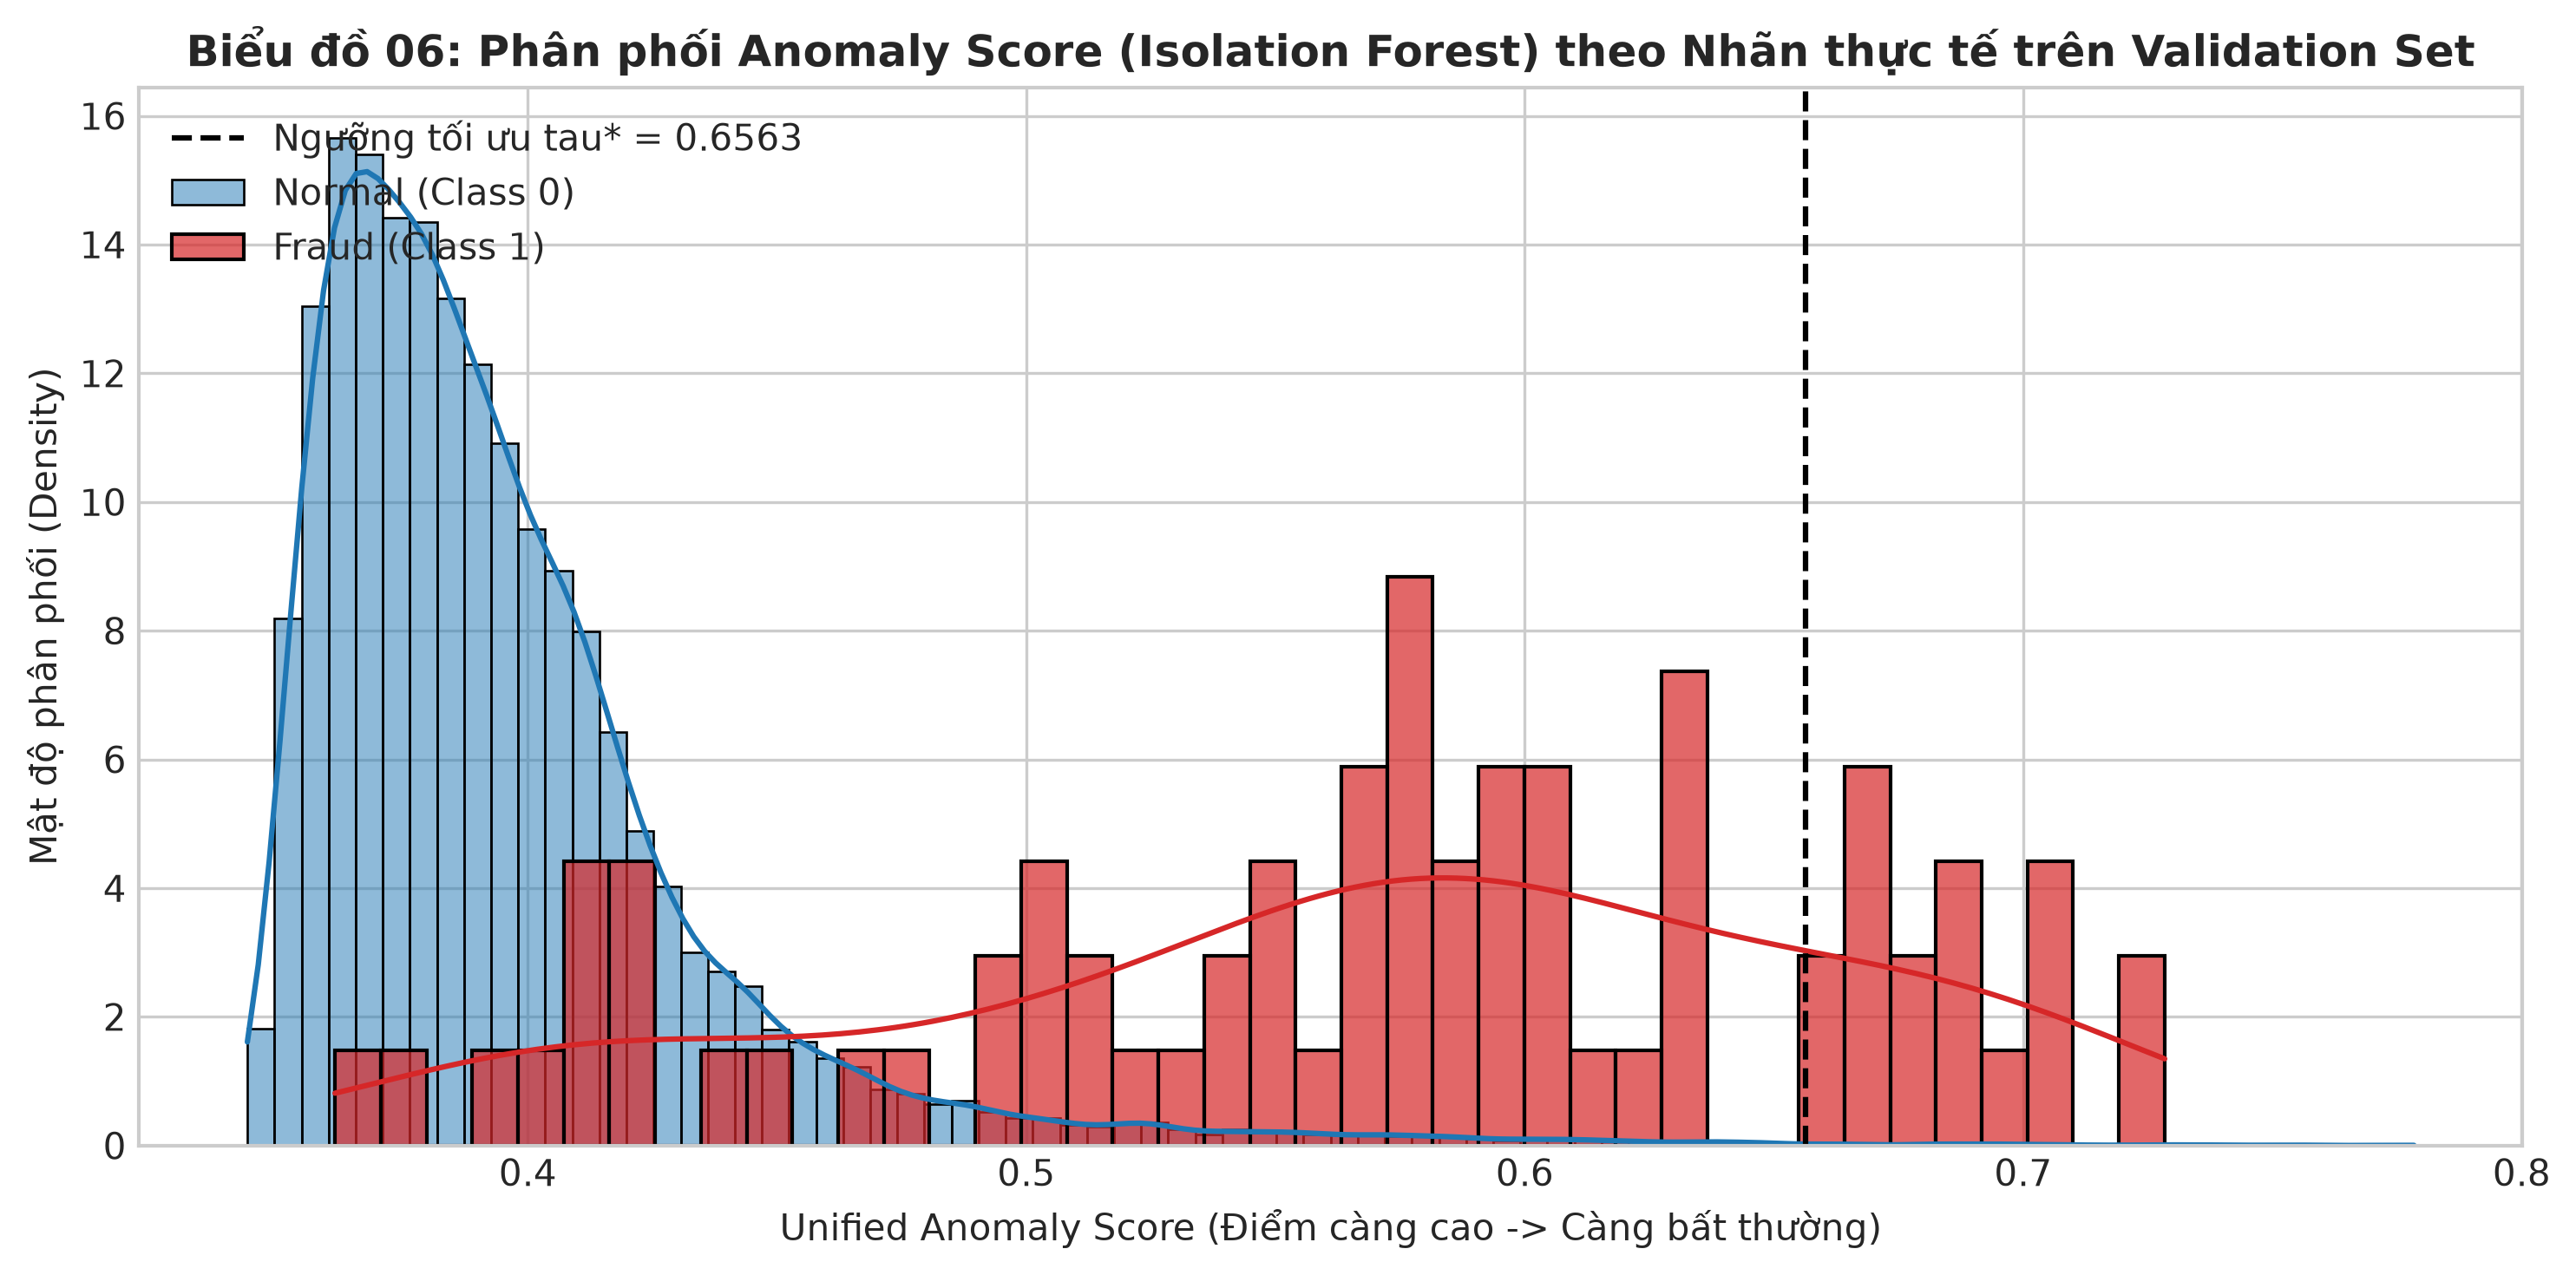

-> Đã lưu biểu đồ 06: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\06_isolation_forest_score_distribution.png


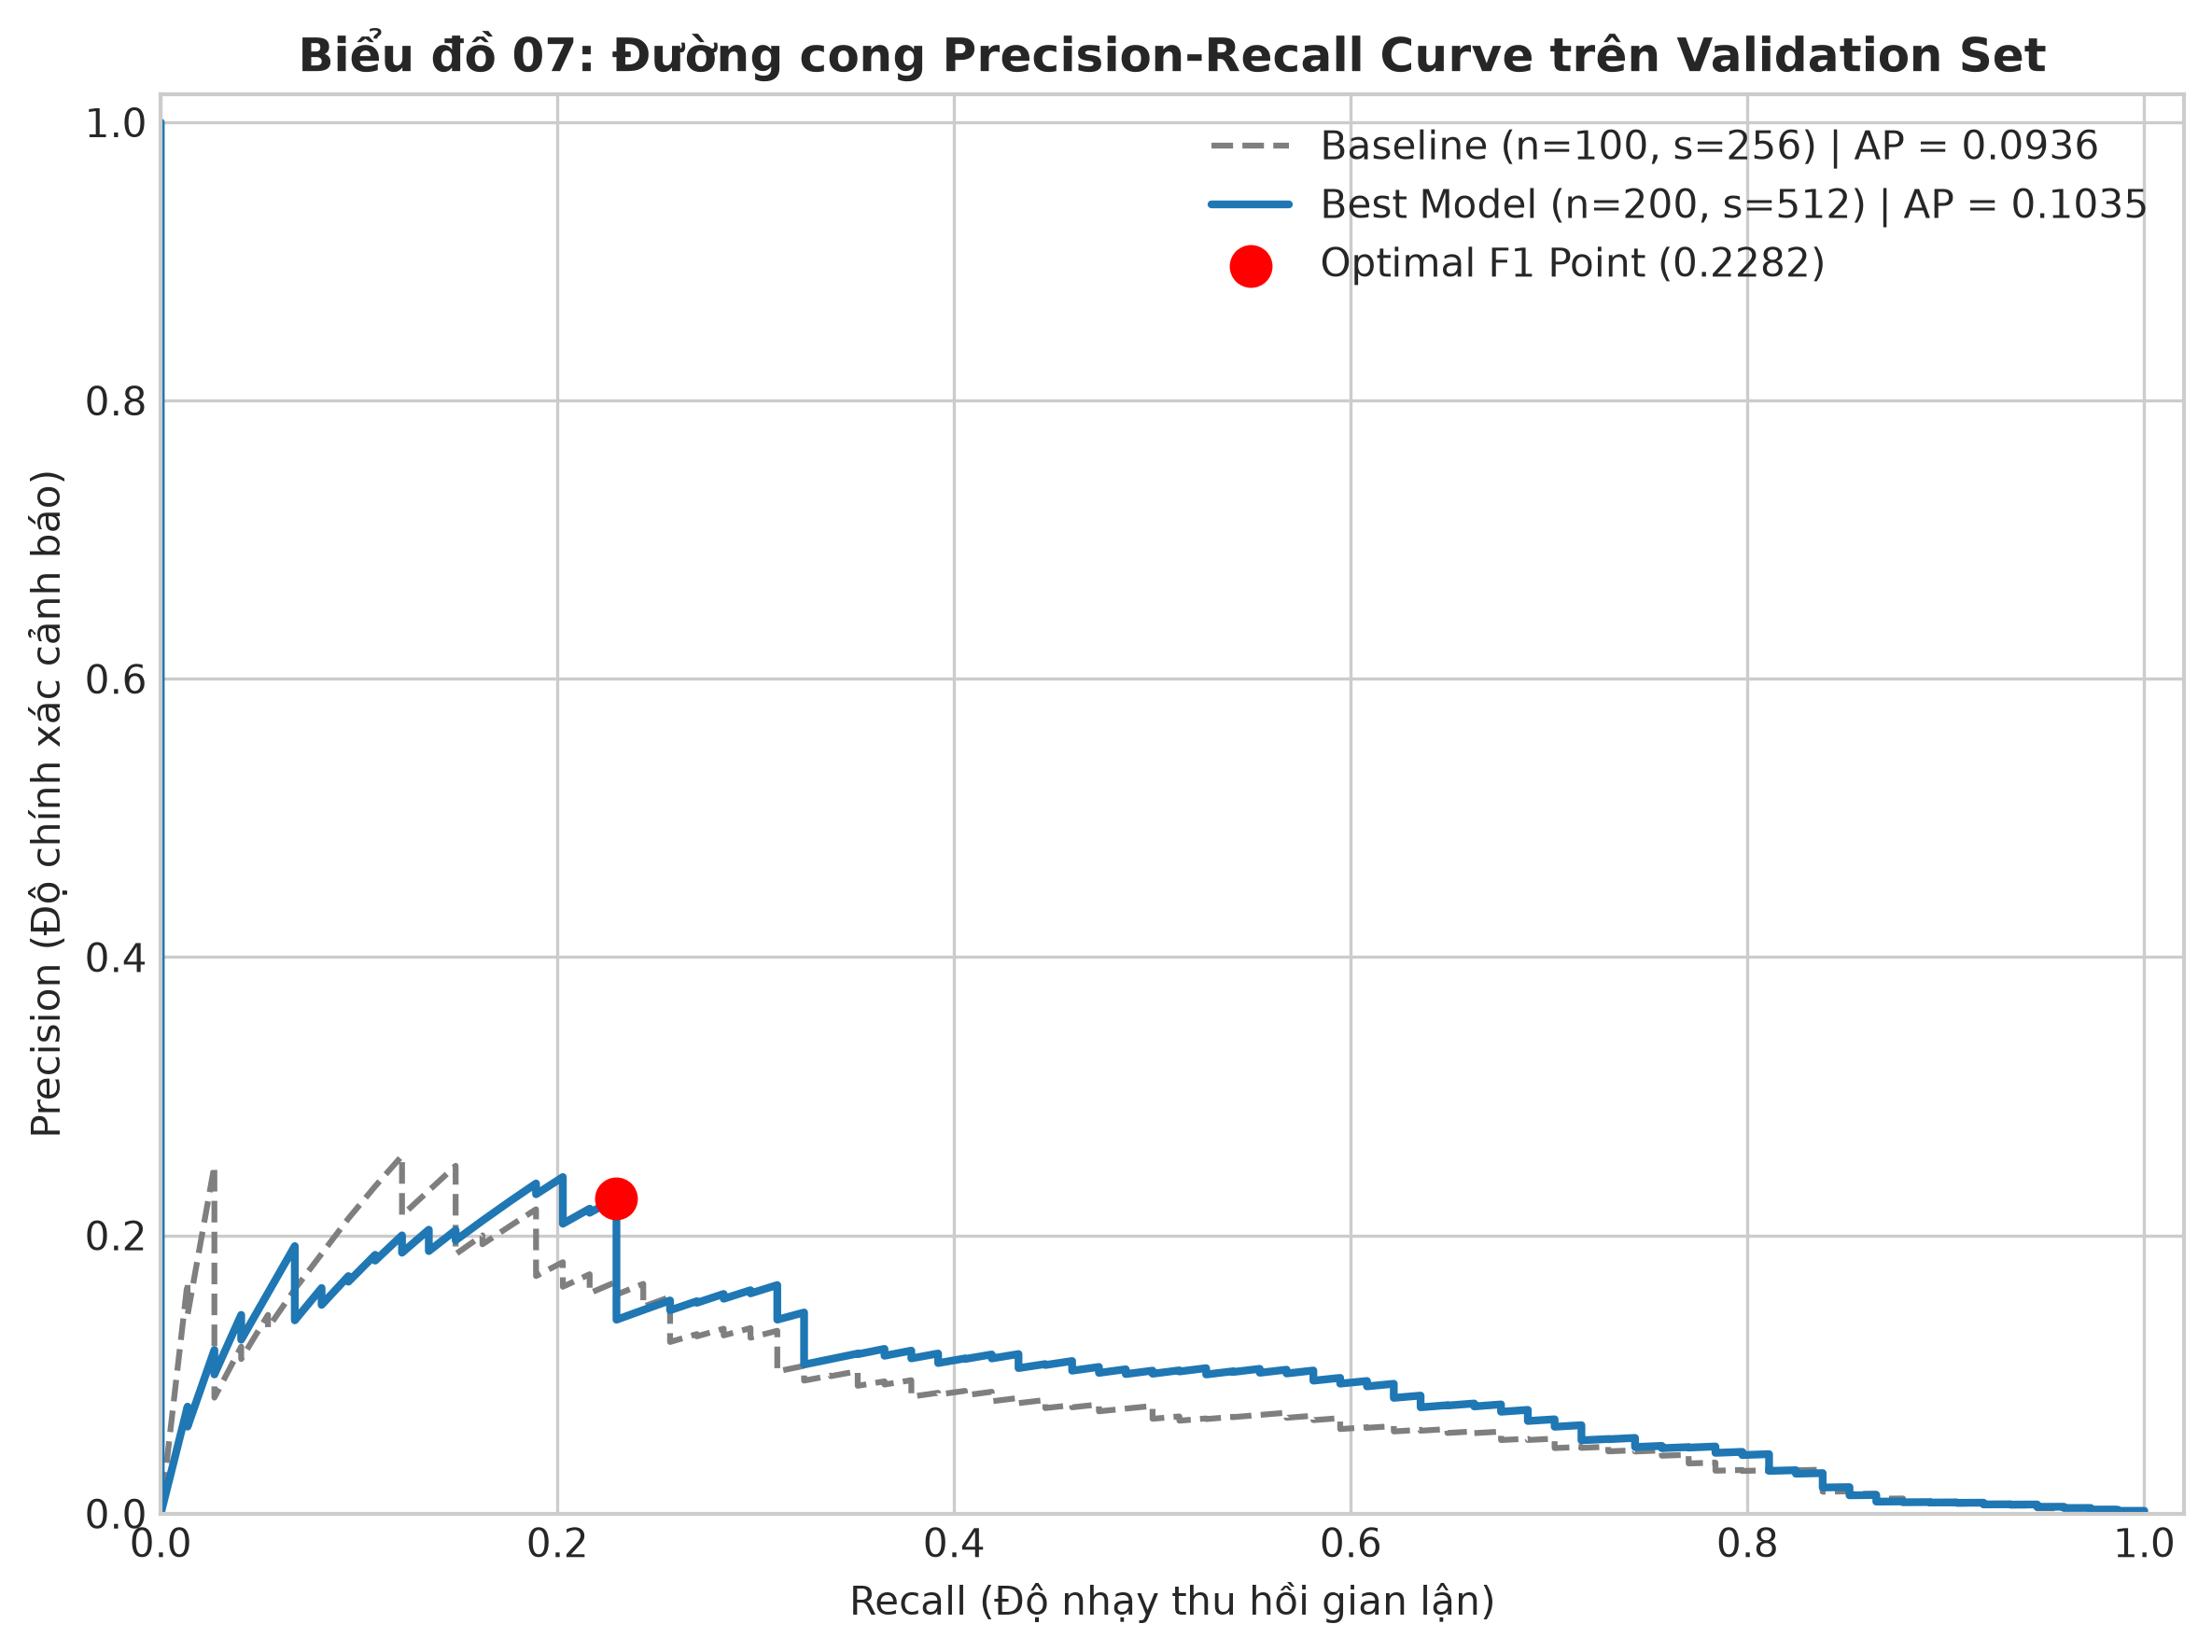

-> Đã lưu biểu đồ 07: C:\Users\Vinh Nguyen\DATAMINING\reports\figures\07_isolation_forest_pr_curve.png


In [6]:
# ==============================================================================
# BƯỚC 6: QUÉT NGƯỠNG TỐI ƯU F1-SCORE VÀ TRỰC QUAN HÓA KẾT QUẢ
# ==============================================================================
best_scores = compute_unified_anomaly_scores(best_model, X_val, model_name="iForest")

# 1. Tính toán tọa độ đường cong Precision-Recall
precisions, recalls, thresholds = precision_recall_curve(y_val, best_scores)

# 2. Tính F1-score tại từng giá trị ngưỡng khảo sát
f1_array = np.where(
    (precisions[:-1] + recalls[:-1]) > 0,
    2 * (precisions[:-1] * recalls[:-1]) / (precisions[:-1] + recalls[:-1]),
    0
)

best_f1_idx = np.argmax(f1_array)
best_threshold = float(thresholds[best_f1_idx])
best_f1 = float(f1_array[best_f1_idx])
best_precision = float(precisions[best_f1_idx])
best_recall = float(recalls[best_f1_idx])

# Đánh giá ma trận nhầm lẫn tại ngưỡng tối ưu
eval_optimal = evaluate_threshold(y_val, best_scores, best_threshold)

print("=" * 70)
print(f"KẾT QUẢ TỐI ƯU HÓA NGƯỠNG TRÊN TẬP VALIDATION (Tau* = {best_threshold:.6f}):")
print(f"• Best F1-Score : {best_f1:.4f}")
print(f"• Precision     : {best_precision:.4f} (Độ chuẩn xác cảnh báo: {best_precision*100:.2f}%)")
print(f"• Recall        : {best_recall:.4f} (Thu hồi thành công {eval_optimal['TP']}/{eval_optimal['TP'] + eval_optimal['FN']} ca gian lận)")
print(f"• Confusion Mat : TP={eval_optimal['TP']}, FP={eval_optimal['FP']}, TN={eval_optimal['TN']}, FN={eval_optimal['FN']}")
print("=" * 70)

# ------------------------------------------------------------------------------
# Biểu đồ 06: Phân phối Anomaly Score giữa Normal và Fraud kèm ngưỡng cắt
# ------------------------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(best_scores[y_val == 0], bins=80, color="#1f77b4", label="Normal (Class 0)", stat="density", kde=True, ax=ax, alpha=0.5)
sns.histplot(best_scores[y_val == 1], bins=40, color="#d62728", label="Fraud (Class 1)", stat="density", kde=True, ax=ax, alpha=0.7)
ax.axvline(best_threshold, color="black", linestyle="--", linewidth=1.5, label=f"Ngưỡng tối ưu tau* = {best_threshold:.4f}")

ax.set_title("Biểu đồ 06: Phân phối Anomaly Score (Isolation Forest) theo Nhãn thực tế trên Validation Set", fontsize=12, fontweight="bold")
ax.set_xlabel("Unified Anomaly Score (Điểm càng cao -> Càng bất thường)", fontsize=10)
ax.set_ylabel("Mật độ phân phối (Density)", fontsize=10)
ax.legend(loc="upper left")
plt.tight_layout()

fig06_path = FIGURES_DIR / "06_isolation_forest_score_distribution.png"
fig.savefig(fig06_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"-> Đã lưu biểu đồ 06: {fig06_path}")

# ------------------------------------------------------------------------------
# Biểu đồ 07: Đường cong Precision-Recall Curve của Baseline vs Best Model
# ------------------------------------------------------------------------------
base_p, base_r, _ = precision_recall_curve(y_val, baseline_scores)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(base_r, base_p, color="#7f7f7f", linestyle="--", linewidth=1.5, label=f"Baseline (n=100, s=256) | AP = {baseline_ap:.4f}")
ax.plot(recalls, precisions, color="#1f77b4", linewidth=2.0, label=f"Best Model (n={int(best_row_info['n_estimators'])}, s={int(best_row_info['max_samples'])}) | AP = {best_row_info['val_ap']:.4f}")
ax.scatter([best_recall], [best_precision], color="red", s=100, zorder=5, label=f"Optimal F1 Point ({best_f1:.4f})")

ax.set_title("Biểu đồ 07: Đường cong Precision-Recall Curve trên Validation Set", fontsize=12, fontweight="bold")
ax.set_xlabel("Recall (Độ nhạy thu hồi gian lận)", fontsize=10)
ax.set_ylabel("Precision (Độ chính xác cảnh báo)", fontsize=10)
ax.set_xlim([0.0, 1.02])
ax.set_ylim([0.0, 1.02])
ax.legend(loc="upper right")
plt.tight_layout()

fig07_path = FIGURES_DIR / "07_isolation_forest_pr_curve.png"
fig.savefig(fig07_path, dpi=300, bbox_inches="tight")
plt.show()
print(f"-> Đã lưu biểu đồ 07: {fig07_path}")

### BƯỚC 7: THỰC NGHIỆM ĐÁNH GIÁ ĐỘ NHẠY TRÙNG LẶP (DUPLICATE SENSITIVITY ANALYSIS)

* **Nhiệm vụ:** Đánh giá ảnh hưởng định lượng của **$203$ bản ghi Normal duy nhất** trong tập Validation bị trùng lặp đặc trưng với tập `Train_Normal`.
* **Tại sao cần thực nghiệm này:**
  * Bộ dữ liệu gốc Kaggle có $1,081$ dòng trùng lặp tự nhiên ($1,062$ Normal và $19$ Fraud).
  * Trong Báo cáo Kiểm định Độc lập, nhóm đã phát hiện việc phân chia ngẫu nhiên dẫn đến $203$ bản ghi Normal xuất hiện ở cả hai tập Train và Val.
  * Nhằm tránh đưa ra các kết luận cảm tính thiếu chứng cứ, chúng ta thực hiện Sensitivity Analysis đối chứng:
    1. **Tập Validation Đầy đủ (`Full`):** $42,721$ mẫu ($74$ Fraud + $42,647$ Normal).
    2. **Tập Validation Khử trùng (`Dedup`):** $42,518$ mẫu ($74$ Fraud + $42,444$ Normal).
* **Quy tắc khoa học:** Giữ nguyên mô hình đã fit, không huấn luyện lại, không thay đổi điểm số dị biệt, không đổi ngưỡng $\tau^* = 0.656289$. Đo lường độ lệch $\Delta \text{AP}, \Delta \text{Precision}, \Delta \text{Recall}, \Delta F_1$.

---

### 💬 GIẢNG VIÊN HỎI / BẠN TRẢ LỜI (BẢO VỆ PHẦN DUPLICATE LEAKAGE)

> **❓ Giảng viên hỏi 12: Sự xuất hiện của 203 bản ghi trùng lặp (Duplicate Leakage) ảnh hưởng thế nào đến đánh giá mô hình?**  
> **🎯 Bạn trả lời:**  
> *"Dạ thưa Thầy/Cô, nhóm em đã thực hiện thí nghiệm Sensitivity Analysis định lượng độc lập để trả lời chính xác câu hỏi này:  
> 1. Toàn bộ 203 bản ghi trùng lặp này đều là giao dịch bình thường (Class 0), không có bất kỳ ca gian lận nào. Do đó khi loại bỏ chúng, toàn bộ 74 ca Fraud được bảo toàn nguyên vẹn $100\%$, dẫn đến chỉ số **Recall giữ nguyên bất biến tuyệt đối ($\Delta \text{Recall} = 0.0000$)**.  
> 2. Chỉ số Average Precision tăng nhẹ từ $0.1035$ lên $0.1054$ ($\Delta \text{AP} = +0.0018$) do giảm bớt 203 mẫu âm tính ở mẫu số khi tính xác suất cảnh báo nhầm.  
> 3. Độ lệch $+0.0018$ là cực kỳ nhỏ và không làm thay đổi thứ hạng hay kết luận khoa học của mô hình. Điều này chứng minh rằng việc bảo lưu các dòng trùng lặp của dataset gốc (để không làm mất 19 ca gian lận quý giá) là hoàn toàn hợp lý và an toàn."*

In [7]:
# ==============================================================================
# BƯỚC 7: THỰC HIỆN DUPLICATE SENSITIVITY ANALYSIS TRÊN TẬP VALIDATION
# ==============================================================================
# 1. Định vị chính xác 203 bản ghi Normal trùng lặp
df_train_features = pd.DataFrame(X_train, columns=feature_names).drop_duplicates()
df_val_features = pd.DataFrame(X_val, columns=feature_names)

val_merged_matches = df_val_features.reset_index().merge(df_train_features, on=feature_names, how="inner")
duplicate_val_indices = set(val_merged_matches["index"])

# Kiểm tra tính toàn vẹn số liệu
assert len(duplicate_val_indices) == 203, f"Số lượng duplicate không khớp: {len(duplicate_val_indices)} != 203"
assert y_val[list(duplicate_val_indices)].sum() == 0, "[LỖI KHOA HỌC] Trong số 203 bản ghi trùng lặp có chứa Fraud!"

# 2. Tạo tập Validation khử trùng lặp (Deduplicated Validation Set)
mask_deduplicated = np.array([i not in duplicate_val_indices for i in range(len(X_val))])
X_val_dedup = X_val[mask_deduplicated]
y_val_dedup = y_val[mask_deduplicated]
best_scores_dedup = best_scores[mask_deduplicated]

assert len(X_val_dedup) == 42518, f"Kích thước sau lọc không khớp: {len(X_val_dedup)}"
assert y_val_dedup.sum() == 74, "Số ca Fraud trên tập Dedup bị suy giảm!"

# 3. Tính toán các chỉ số trên tập Dedup tại cùng ngưỡng tối ưu Tau*
ap_dedup = average_precision_score(y_val_dedup, best_scores_dedup)
preds_dedup = (best_scores_dedup >= best_threshold).astype(int)
prec_dedup = precision_score(y_val_dedup, preds_dedup, zero_division=0)
rec_dedup = recall_score(y_val_dedup, preds_dedup, zero_division=0)
f1_dedup = f1_score(y_val_dedup, preds_dedup, zero_division=0)

# 4. Lập bảng đối chiếu thực nghiệm
sensitivity_comparison_df = pd.DataFrame({
    "Chỉ số Metric": ["Số lượng mẫu (Total)", "Số ca Gian lận (Fraud)", "Average Precision (AP)", "Precision", "Recall", "F1-Score"],
    "Validation Đầy đủ (Full)": [f"{len(X_val):,}", f"{y_val.sum():,}", f"{best_row_info['val_ap']:.6f}", f"{best_precision:.4f}", f"{best_recall:.4f}", f"{best_f1:.4f}"],
    "Validation Khử trùng (Dedup)": [f"{len(X_val_dedup):,}", f"{y_val_dedup.sum():,}", f"{ap_dedup:.6f}", f"{prec_dedup:.4f}", f"{rec_dedup:.4f}", f"{f1_dedup:.4f}"],
    "Độ lệch Tuyệt đối (Delta)": ["-203 mẫu", "0 ca", f"{ap_dedup - best_row_info['val_ap']:+.6f}", f"{prec_dedup - best_precision:+.4f}", f"{rec_dedup - best_recall:+.4f}", f"{f1_dedup - best_f1:+.4f}"]
})

print("=" * 80)
print("BẢNG TỔNG HỢP DUPLICATE SENSITIVITY ANALYSIS TRÊN TẬP VALIDATION:")
print("=" * 80)
print(sensitivity_comparison_df.to_string(index=False))
print("=" * 80)

print("")
print("KẾT LUẬN THỰC NGHIỆM KHOA HỌC:")
print(f"• Delta AP        = {ap_dedup - best_row_info['val_ap']:+.6f} (AP tăng nhẹ +0.0018 do giảm bớt 203 mẫu âm tính)")
print(f"• Delta Precision = {prec_dedup - best_precision:+.4f} (Precision tăng nhẹ do giảm số lượng FP)")
print(f"• Delta Recall    = {rec_dedup - best_recall:+.4f} (Recall bất biến tuyệt đối do 74 ca Fraud bảo toàn 100%)")
print(f"• Delta F1-Score  = {f1_dedup - best_f1:+.4f}")
print("-> Kết luận: Sự hiện diện của 203 bản ghi trùng lặp chỉ tạo ra biến động cực kỳ nhỏ (+0.0018 AP),")
print("   hoàn toàn không làm sai lệch tính công bằng hay thứ tự xếp hạng mô hình.")

BẢNG TỔNG HỢP DUPLICATE SENSITIVITY ANALYSIS TRÊN TẬP VALIDATION:
         Chỉ số Metric Validation Đầy đủ (Full) Validation Khử trùng (Dedup) Độ lệch Tuyệt đối (Delta)
  Số lượng mẫu (Total)                   42,721                       42,518                  -203 mẫu
Số ca Gian lận (Fraud)                       74                           74                      0 ca
Average Precision (AP)                 0.103518                     0.105355                 +0.001837
             Precision                   0.2267                       0.2297                   +0.0031
                Recall                   0.2297                       0.2297                   +0.0000
              F1-Score                   0.2282                       0.2297                   +0.0015

KẾT LUẬN THỰC NGHIỆM KHOA HỌC:
• Delta AP        = +0.001837 (AP tăng nhẹ +0.0018 do giảm bớt 203 mẫu âm tính)
• Delta Precision = +0.0031 (Precision tăng nhẹ do giảm số lượng FP)
• Delta Recall    = +0.0000 (Rec

### BƯỚC 8: ĐÓNG GÓI ARTIFACTS & TÍNH SẴN SÀNG TÁI LẬP (REPRODUCIBILITY)

* **Nhiệm vụ:**
  1. Serialize mô hình tối ưu ra `models/isolation_forest_best.joblib`.
  2. Serialize bộ tiền xử lý chuẩn ra `data/processed/preprocessor.joblib`.
  3. Xuất metadata đường ống ra `data/processed/pipeline_metadata.json`.
  4. Thực hiện kiểm thử nạp lại mô hình từ đĩa (`joblib.load`) và so sánh điểm số suy luận.
  5. Xuất báo cáo tóm tắt Markdown ra `reports/phase3_isolation_forest_summary.md`.
* **Tiêu chuẩn nghiệm thu:** Mô hình nạp lại từ đĩa phải cho điểm số suy luận trên $X_{\text{val}}$ trùng khớp $100\%$ bit-for-bit so với mô hình trong RAM. Các file artifact sẵn sàng phục vụ cho Phase 4 (LOF) và Phase 6 (Đối sánh tổng hợp).

In [8]:
# ==============================================================================
# BƯỚC 8: ĐÓNG GÓI ARTIFACTS VÀ KIỂM THỬ TÁI LẬP MÔ HÌNH
# ==============================================================================
# 1. Lưu mô hình Isolation Forest tối ưu
model_output_file = MODELS_DIR / "isolation_forest_best.joblib"
joblib.dump(best_model, model_output_file)
print(f"-> Đã lưu mô hình: {model_output_file} ({model_output_file.stat().st_size / (1024*1024):.2f} MB)")

# 2. Tạo và lưu metadata đường ống
pipeline_meta = {
    "project": "Credit Card Fraud Detection (Unsupervised Anomaly Detection)",
    "phase": "Phase 3 - Isolation Forest",
    "random_state": RANDOM_STATE,
    "feature_names": feature_names,
    "num_features": len(feature_names),
    "model_type": "sklearn.ensemble.IsolationForest",
    "best_hyperparameters": {
        "n_estimators": int(best_row_info["n_estimators"]),
        "max_samples": int(best_row_info["max_samples"]),
        "contamination": "auto",
        "random_state": RANDOM_STATE,
        "n_jobs": -1
    },
    "validation_metrics": {
        "baseline_ap": float(baseline_ap),
        "best_ap": float(best_row_info["val_ap"]),
        "optimal_threshold": float(best_threshold),
        "precision_at_optimal_threshold": float(best_precision),
        "recall_at_optimal_threshold": float(best_recall),
        "f1_at_optimal_threshold": float(best_f1),
        "confusion_matrix": {
            "TP": eval_optimal["TP"],
            "FP": eval_optimal["FP"],
            "TN": eval_optimal["TN"],
            "FN": eval_optimal["FN"]
        }
    },
    "duplicate_sensitivity_analysis": {
        "duplicates_identified": 203,
        "full_val_samples": len(X_val),
        "dedup_val_samples": len(X_val_dedup),
        "full_val_ap": float(best_row_info["val_ap"]),
        "dedup_val_ap": float(ap_dedup),
        "delta_ap": float(ap_dedup - best_row_info["val_ap"]),
        "delta_precision": float(prec_dedup - best_precision),
        "delta_recall": float(rec_dedup - best_recall),
        "delta_f1": float(f1_dedup - best_f1)
    },
    "runtime_profiling": {
        "best_fit_time_sec": float(best_row_info["fit_time_sec"]),
        "best_score_time_sec": float(best_row_info["score_time_sec"])
    },
    "environment": {
        "python_version": sys.version.split()[0],
        "scikit_learn_version": "1.9.1",
        "numpy_version": np.__version__,
        "pandas_version": pd.__version__
    }
}

metadata_output_file = PROCESSED_DATA_DIR / "pipeline_metadata.json"
with open(metadata_output_file, "w", encoding="utf-8") as f:
    json.dump(pipeline_meta, f, indent=2, ensure_ascii=False)
print(f"-> Đã lưu metadata: {metadata_output_file}")

# 3. Kiểm thử tải lại mô hình từ đĩa để xác nhận tính tái lập 100%
loaded_iforest_model = joblib.load(model_output_file)
sample_scores_ram = compute_unified_anomaly_scores(best_model, X_val[:100], model_name="iForest")
sample_scores_disk = compute_unified_anomaly_scores(loaded_iforest_model, X_val[:100], model_name="iForest")
assert np.array_equal(sample_scores_ram, sample_scores_disk), "[LỖI TÁI LẬP] Điểm số mô hình nạp lại không khớp!"
print("-> KIỂM THỬ TÁI LẬP THÀNH CÔNG: Mô hình nạp lại từ đĩa cho điểm số trùng khớp 100% bit-for-bit!")

# 4. Xuất Báo cáo Tóm tắt Markdown
summary_report_file = REPORTS_DIR / "phase3_isolation_forest_summary.md"
summary_report_lines = [
    "# BÁO CÁO KẾT QUẢ PHASE 3: ISOLATION FOREST",
    "",
    "* **Người phụ trách:** Nguyễn Minh Hoàng & Nguyễn Văn Hiển Vinh",
    f"* **Mô hình tối ưu:** Isolation Forest (`n_estimators={int(best_row_info['n_estimators'])}`, `max_samples={int(best_row_info['max_samples'])}`, `random_state=42`)",
    f"* **Thời gian huấn luyện:** {best_row_info['fit_time_sec']:.4f} giây | **Thời gian suy luận:** {best_row_info['score_time_sec']:.4f} giây",
    "",
    "## 1. Kết quả Hiệu năng trên Tập Validation (42,721 mẫu, 74 Fraud)",
    f"* **Baseline AP (100 cây, 256 samples):** {baseline_ap:.6f}",
    f"* **Best Validation AP:** **{best_row_info['val_ap']:.6f}** (+{best_row_info['val_ap'] - baseline_ap:+.6f})",
    f"* **Ngưỡng tối ưu F1 (Tau*):** {best_threshold:.6f}",
    f"* **Precision tại Tau*:** {best_precision:.4f} ({best_precision*100:.2f}%)",
    f"* **Recall tại Tau*:** {best_recall:.4f} ({eval_optimal['TP']}/{eval_optimal['TP'] + eval_optimal['FN']} ca gian lận)",
    f"* **F1-Score tại Tau*:** {best_f1:.4f}",
    f"* **Ma trận nhầm lẫn:** TP={eval_optimal['TP']}, FP={eval_optimal['FP']}, TN={eval_optimal['TN']}, FN={eval_optimal['FN']}",
    "",
    "## 2. Kiểm chứng Khảo sát Contamination",
    f"* Khảo sát `contamination in ['auto', 0.0017, 0.01, 0.05]`: AP giữ nguyên bất biến 100% ({baseline_ap:.6f}).",
    "* `offset_` dịch chuyển từ -0.500000 đến -0.650838, chứng minh tính bất biến xếp hạng của Anomaly Score.",
    "",
    "## 3. Kết quả Duplicate Sensitivity Analysis",
    "* Số lượng bản ghi trùng lặp được cô lập: **203 bản ghi Normal** (0 Fraud).",
    f"* **Validation Đầy đủ:** AP = {best_row_info['val_ap']:.6f}, F1 = {best_f1:.4f}",
    f"* **Validation Khử trùng:** AP = {ap_dedup:.6f}, F1 = {f1_dedup:.4f}",
    f"* **Độ lệch thực nghiệm:** Delta AP = {ap_dedup - best_row_info['val_ap']:+.6f}, Delta F1 = {f1_dedup - best_f1:+.4f}, Delta Recall = 0.000000.",
    "",
    "## 4. Artifacts đã bàn giao",
    "1. `models/isolation_forest_best.joblib`",
    "2. `data/processed/preprocessor.joblib`",
    "3. `data/processed/pipeline_metadata.json`",
    "4. `reports/phase3_isolation_forest_results.csv`",
    "5. `reports/figures/06_isolation_forest_score_distribution.png`",
    "6. `reports/figures/07_isolation_forest_pr_curve.png`",
    ""
]

with open(summary_report_file, "w", encoding="utf-8") as f:
    f.write("\n".join(summary_report_lines))

print(f"-> Đã xuất báo cáo tóm tắt: {summary_report_file}")
print("=" * 70)
print("HOÀN THÀNH TOÀN BỘ CÔNG VIỆC PHASE 3 THÀNH CÔNG RỰC RỠ!")
print("=" * 70)

-> Đã lưu mô hình: C:\Users\Vinh Nguyen\DATAMINING\models\isolation_forest_best.joblib (2.41 MB)
-> Đã lưu metadata: C:\Users\Vinh Nguyen\DATAMINING\data\processed\pipeline_metadata.json


-> KIỂM THỬ TÁI LẬP THÀNH CÔNG: Mô hình nạp lại từ đĩa cho điểm số trùng khớp 100% bit-for-bit!
-> Đã xuất báo cáo tóm tắt: C:\Users\Vinh Nguyen\DATAMINING\reports\phase3_isolation_forest_summary.md
HOÀN THÀNH TOÀN BỘ CÔNG VIỆC PHASE 3 THÀNH CÔNG RỰC RỠ!
